## This Part of the work contains Exploratory Data Analysis and Topic Modelling. The Rmd file in the Zip Folder has the other part of the Work.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_excel('/content/Dataset.xlsx')
df.head()

,PostID,Post Description,Date,Language Code,Full Language,Sentiment
0,B7mbLCVhYIf,QUESTIONS AND ANSWERS ON CORONAVIRUS PT. 2\n\n...,01/21/2020,en,English,positive
1,B7o2ozppOnS,#Viral China no deja salir a #11millones de ci...,01/22/2020,es,Spanish,negative
2,B7nMy1Xl7st,Önce tedbir sonra tevekkül inşallah. Wuhanda o...,01/22/2020,tr,Turkish,negative
3,B7m7M3SgvI1,Using humor to bring attention to a serious ma...,01/22/2020,en,English,negative
4,B7oK_DMhtxr,Stay safe\nCover your face\n#typ262 #40mm #40m...,01/22/2020,en,English,positive


## Dataset Overview

Checking the number of records and values in each column

In [ ]:
df.describe()

,PostID,Post Description,Date,Language Code,Full Language,Sentiment
count,500153,500153,500153,500153,500153,500153
unique,500153,395752,1708,161,161,3
top,DAQ7C3LuZ0w,#covid_19 #covid19 #covıd19 #covidnurses #covi...,08/15/2024,en,English,neutral
freq,1,932,1808,343041,343041,237164


In [ ]:
df.isna().sum()

,0
PostID,0
Post Description,0
Date,0
Language Code,0
Full Language,0
Sentiment,0


In [ ]:
df.shape

(500153, 6)

Data Distribution

Total number of posts per language

In [ ]:
df['Full Language'].unique()

array(['English', 'Spanish', 'Turkish', 'Indonesian', 'Afrikaans', 'Thai',
       'Kannada', 'Arabic', 'Bulgarian', 'Polish', 'Russian',
       'Chinese (Traditional)', 'Dutch', 'Malay', 'Malayalam', 'Hindi',
       'Chinese (Simplified)', 'Telugu', 'Italian', 'Khmer', 'Portuguese',
       'Tamil', 'German', 'Cebuano', 'Persian', 'Tatar', 'Urdu', 'French',
       'Waray-Waray', 'Swahili', 'Somali', 'Azerbaijani', 'Marathi',
       'Guarani', 'Sindhi', 'Japanese', 'Gujarati', 'Uzbek', 'Bengali',
       'Kinyarwanda', 'Filipino', 'Madurese', 'Armenian', 'Swedish',
       'Oromo', 'Latvian', 'Iloko', 'Sinhala', 'Punjabi', 'Ukrainian',
       'Assamese', 'Maithili', 'Hausa', 'Pashto', 'Odia (Oriya)', 'Welsh',
       'Kurdish (Sorani)', 'Danish', 'Romanian', 'Konkani', 'Nepali',
       'Hebrew', 'Dari (Persian - Afghanistan)', 'Norwegian', 'Yoruba',
       'Finnish', 'Estonian', 'Haitian Creole', 'Occitan', 'Latin',
       'Afar', 'Hungarian', 'Slovenian', 'Greenlandic', 'Igbo', 'Tulu',
   

In [ ]:
df['Full Language'].value_counts()

,count
Full Language,
English,343041
Spanish,30220
Hindi,15832
Portuguese,15779
Indonesian,11491
...,...
Fulah,1
Fijian,1
Newari,1


In [ ]:
language_counts = df['Full Language'].value_counts().reset_index()
language_counts.columns = ['Language', 'Post Count']
language_counts.head(10)

,Language,Post Count
0,English,343041
1,Spanish,30220
2,Hindi,15832
3,Portuguese,15779
4,Indonesian,11491
5,Tamil,9592
6,Arabic,9416
7,German,7822
8,Italian,5162
9,Turkish,4632


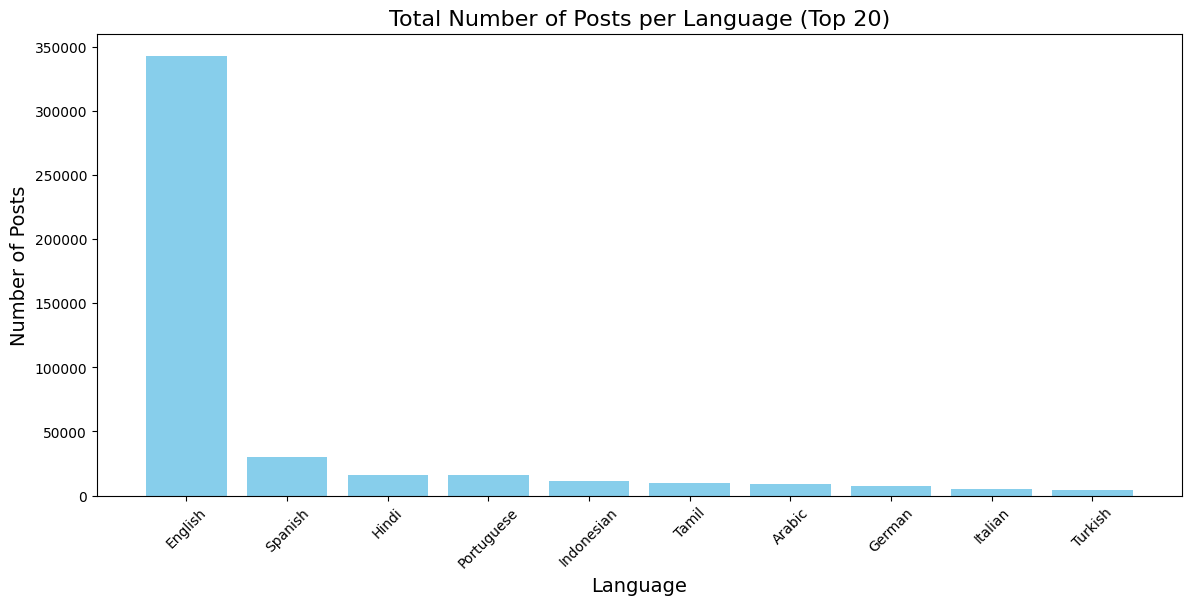

In [ ]:
plt.figure(figsize=(14, 6))
plt.bar(language_counts['Language'][:10], language_counts['Post Count'][:10], color='skyblue')
plt.title('Total Number of Posts per Language (Top 20)', fontsize=16)
plt.xlabel('Language', fontsize=14)
plt.ylabel('Number of Posts', fontsize=14)
plt.xticks(rotation=45)
plt.show()

 distribution of sentiments (positive, negative, neutral) across the top 5 languages.



In [ ]:
df['Sentiment'].unique()

array(['positive', 'negative', 'neutral'], dtype=object)

In [ ]:
import seaborn as sns

In [ ]:
top_5_languages =  df['Full Language'].value_counts().head(5).index.tolist()
top_5_languages

['English', 'Spanish', 'Hindi', 'Portuguese', 'Indonesian']

In [ ]:
filtered_df = df[df['Full Language'].isin(top_5_languages)]

In [ ]:
sentiment_counts = filtered_df.groupby(['Full Language', 'Sentiment']).size().reset_index(name='Count')

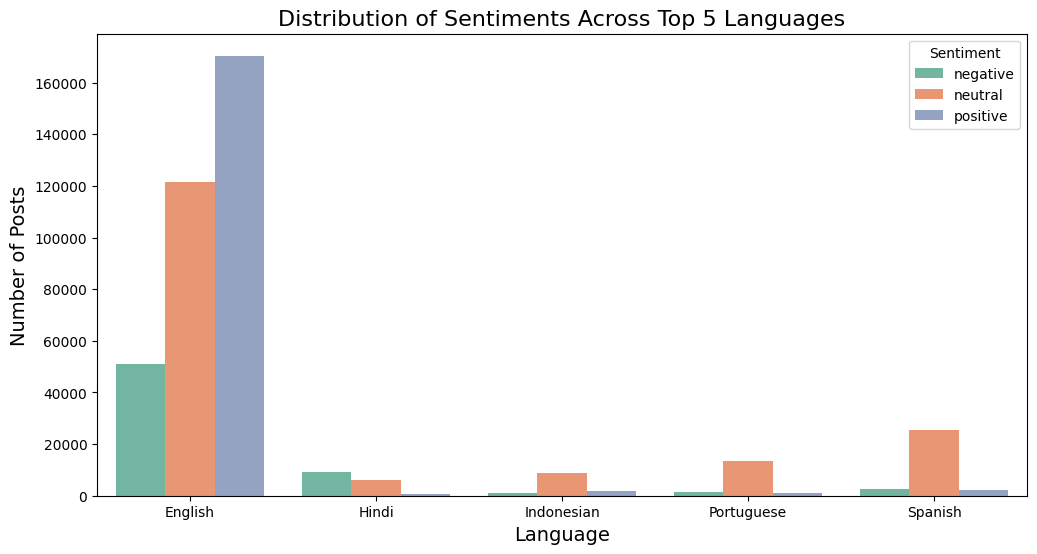

In [ ]:
# Plotting the distribution of sentiments for top 5 languages
plt.figure(figsize=(12, 6))
sns.barplot(x='Full Language', y='Count', hue='Sentiment', data=sentiment_counts, palette='Set2')
plt.title('Distribution of Sentiments Across Top 5 Languages', fontsize=16)
plt.xlabel('Language', fontsize=14)
plt.ylabel('Number of Posts', fontsize=14)
plt.show()

Time Range of the dataset

In [ ]:
# Convert the 'Date' column to datetime format
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')

# Find the minimum and maximum dates
start_date = df['Date'].min()
end_date = df['Date'].max()

# Display the time range
print(f"Time range of the dataset: {start_date.date()} to {end_date.date()}")

Time range of the dataset: 2020-01-21 to 2024-09-23


Sentiment Analysis Trends

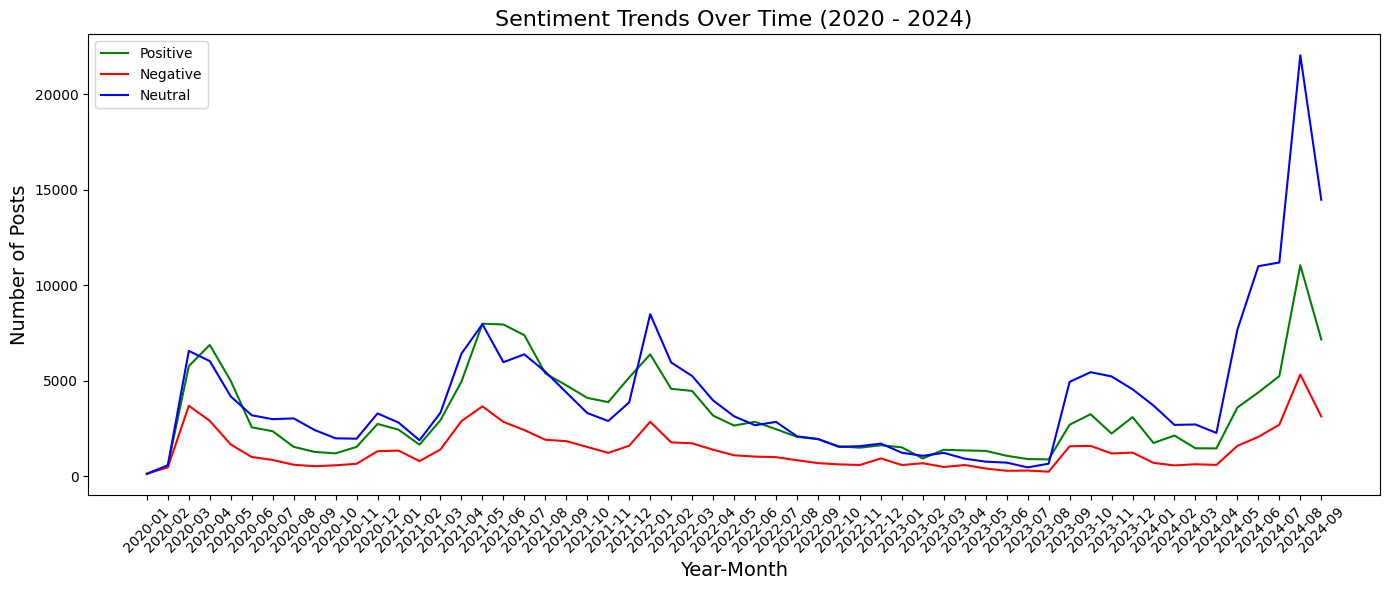

In [ ]:
# Extract the Year and Month from the 'Date' column to group by month
df['YearMonth'] = df['Date'].dt.to_period('M')

# Count sentiment occurrences per month
sentiment_trends = df.groupby(['YearMonth', 'Sentiment']).size().reset_index(name='Count')

# Pivoting the data for better visualization
sentiment_pivot = sentiment_trends.pivot(index='YearMonth', columns='Sentiment', values='Count').fillna(0)

# Plotting the sentiment trends over time
plt.figure(figsize=(14, 6))
plt.plot(sentiment_pivot.index.astype(str), sentiment_pivot['positive'], label='Positive', color='green')
plt.plot(sentiment_pivot.index.astype(str), sentiment_pivot['negative'], label='Negative', color='red')
plt.plot(sentiment_pivot.index.astype(str), sentiment_pivot['neutral'], label='Neutral', color='blue')
plt.title('Sentiment Trends Over Time (2020 - 2024)', fontsize=16)
plt.xlabel('Year-Month', fontsize=14)
plt.ylabel('Number of Posts', fontsize=14)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Creating a new dataframe for only english and spanish

In [ ]:
df

,PostID,Post Description,Date,Language Code,Full Language,Sentiment,YearMonth
0,B7mbLCVhYIf,QUESTIONS AND ANSWERS ON CORONAVIRUS PT. 2\n\n...,2020-01-21,en,English,positive,2020-01
1,B7o2ozppOnS,#Viral China no deja salir a #11millones de ci...,2020-01-22,es,Spanish,negative,2020-01
2,B7nMy1Xl7st,Önce tedbir sonra tevekkül inşallah. Wuhanda o...,2020-01-22,tr,Turkish,negative,2020-01
3,B7m7M3SgvI1,Using humor to bring attention to a serious ma...,2020-01-22,en,English,negative,2020-01
4,B7oK_DMhtxr,Stay safe\nCover your face\n#typ262 #40mm #40m...,2020-01-22,en,English,positive,2020-01
...,...,...,...,...,...,...,...
500148,DAN7BsTuBrG,"👀Vacaciones en Argentina, todo lo que tenés qu...",2024-09-22,es,Spanish,neutral,2024-09
500149,DARcSwAB8NH,✨Care for COVID: Crafting Day Recap🤩🫶\n\nThank...,2024-09-23,en,English,positive,2024-09
500150,DARz37eIGCX,Feliz día internacional de la enfermería!!! Es...,2024-09-23,es,Spanish,positive,2024-09
500151,DAQ-rPtRp3D,"En cette période de confinement, je vous envoi...",2024-09-23,fr,French,negative,2024-09


In [ ]:
new_df = df[df['Full Language'].isin(['English', 'Spanish'])]

new_df['Full Language'].unique()

array(['English', 'Spanish'], dtype=object)

In [ ]:
new_df.to_csv('eng_es.csv', index=False)

## Translating The Spanish Posts to English Using Google Translator

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/content/eng_es.csv')
df.head()

,PostID,Post Description,Date,Language Code,Full Language,Sentiment,YearMonth
0,B7mbLCVhYIf,QUESTIONS AND ANSWERS ON CORONAVIRUS PT. 2\n\n...,2020-01-21,en,English,positive,2020-01
1,B7o2ozppOnS,#Viral China no deja salir a #11millones de ci...,2020-01-22,es,Spanish,negative,2020-01
2,B7m7M3SgvI1,Using humor to bring attention to a serious ma...,2020-01-22,en,English,negative,2020-01
3,B7oK_DMhtxr,Stay safe\nCover your face\n#typ262 #40mm #40m...,2020-01-22,en,English,positive,2020-01
4,B7njeFbBX5y,Did you know an outbreak of a new coronavirus ...,2020-01-22,en,English,negative,2020-01


Filter the Spanish and English posts

In [ ]:
spanish_df = df[df['Full Language'] == 'Spanish'].copy()
english_df = df[df['Full Language'] == 'English'].copy()

In [ ]:
!pip install googletrans==3.1.0a0
from googletrans import Translator
from tqdm import tqdm

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.1/55.1 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.6/42.6 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.0/65.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.6/53.6 kB 3.6 MB/s eta 0:00:00
  Created wheel for googletrans: filename=googletrans-3.1.0a0-py3-none-any.whl size=16353 sha256=ad1f5050c86badd06968f3ff5ef6a038687179f399f8b0eb97cab742193ae5a3
  Stored in directory: /root/.cache/pip/wheels/81/f2/e0/d578821d723b473d18610ea93810e4a5402463919f07e603d9
Successfully built googletrans
  Attempting uninstall: hyperframe
    Found existing installation: hyperframe 6.1.0
    Uninstalling hyperframe

In [ ]:
translator = Translator()

# Translate with progress bar
translated_texts = []
for text in tqdm(spanish_df['Post Description'], desc="Translating Spanish to English"):
    try:
        translated = translator.translate(text, src='es', dest='en')
        translated_texts.append(translated.text)
    except:
        translated_texts.append(text)  # fallback to original if translation fails

Translating Spanish to English: 100%|██████████| 30220/30220 [5:15:21<00:00,  1.60it/s]


In [ ]:
spanish_df['translated_text'] = translated_texts

In [ ]:
# Standardize the column names for English text
english_df['translated_text'] = english_df['Post Description']

# Combine translated Spanish with English
combined_df = pd.concat([english_df, spanish_df], ignore_index=True)

In [ ]:
combined_df.head()

,PostID,Post Description,Date,Language Code,Full Language,Sentiment,YearMonth,translated_text
0,B7mbLCVhYIf,QUESTIONS AND ANSWERS ON CORONAVIRUS PT. 2\n\n...,2020-01-21,en,English,positive,2020-01,QUESTIONS AND ANSWERS ON CORONAVIRUS PT. 2\n\n...
1,B7m7M3SgvI1,Using humor to bring attention to a serious ma...,2020-01-22,en,English,negative,2020-01,Using humor to bring attention to a serious ma...
2,B7oK_DMhtxr,Stay safe\nCover your face\n#typ262 #40mm #40m...,2020-01-22,en,English,positive,2020-01,Stay safe\nCover your face\n#typ262 #40mm #40m...
3,B7njeFbBX5y,Did you know an outbreak of a new coronavirus ...,2020-01-22,en,English,negative,2020-01,Did you know an outbreak of a new coronavirus ...
4,B7nV26QgOLP,It’s so sad and scary that the coronavirus has...,2020-01-22,en,English,negative,2020-01,It’s so sad and scary that the coronavirus has...


Saving the translated CSV file

In [ ]:
combined_df.to_csv('translated_sentiment_data.csv', index=False)

## Topic Modelling

In [ ]:
import numpy as np
print(np.__version__)

1.24.4


In [ ]:
!pip uninstall numpy
!pip install numpy==1.24.4

Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Would remove:
    /usr/local/bin/f2py
    /usr/local/bin/numpy-config
    /usr/local/lib/python3.11/dist-packages/numpy-2.0.2.dist-info/*
    /usr/local/lib/python3.11/dist-packages/numpy.libs/libgfortran-040039e1-0352e75f.so.5.0.0
    /usr/local/lib/python3.11/dist-packages/numpy.libs/libquadmath-96973f99-934c22de.so.0.0.0
    /usr/local/lib/python3.11/dist-packages/numpy.libs/libscipy_openblas64_-99b71e71.so
    /usr/local/lib/python3.11/dist-packages/numpy/*
Proceed (Y/n)? Y
  Successfully uninstalled numpy-2.0.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 62.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jaxlib 0.5.1 requires numpy>=1.25, but you have numpy 1.24.4 which is incompatible.
jax 0.5.2 requires numpy>=1.25, but you have numpy 1.24.4 which is inco

In [ ]:
# Installing gensim
!pip install gensim

import pandas as pd
import nltk
import re
from nltk.corpus import stopwords
from gensim import corpora, models
import gensim
import matplotlib.pyplot as plt

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Loading dataset
df = pd.read_csv('/content/translated_sentiment_data.csv')

# Droping NA and lowercase from the text
df = df.dropna(subset=['post'])
df['post'] = df['post'].str.lower()

# Custom stopwords
custom_stopwords = set([
    "covid", "coronavirus", "covidtesting", "covidpandemic", "covidvaccine",
    "covidupdate", "coronavirusupdates", "coronaviruspandemic",
    "link", "https", "bio", "india", "covid_19", "19", "covid19"
])
stop_words.update(custom_stopwords)

# Cleaning and tokenizing
def preprocess(text):
    tokens = re.findall(r'\b[a-z]{3,}\b', text)  # keep words with at least 3 letters
    return [word for word in tokens if word not in stop_words]

df['tokens'] = df['post'].apply(preprocess)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.7/26.7 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.6/38.6 MB 9.8 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.15.3
    Uninstalling scipy-1.15.3:
      Successfully uninstalled scipy-1.15.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jaxlib 0.5.1 requires numpy>=1.25, but you have numpy 1.24.4 which is incompatible.
jax 0.5.2 requires numpy>=1.25, but you have numpy 1.24.4 which is incompatible.
pymc 5.22.0 requires numpy>=1.25.0, but you have numpy 1.24.4 which is incompatible.
tsfresh 0.21.0 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Creating dictionary and document-term matrix

In [ ]:
dictionary = corpora.Dictionary(df['tokens'])
corpus = [dictionary.doc2bow(text) for text in df['tokens']]

Find Optimal Number of Topics

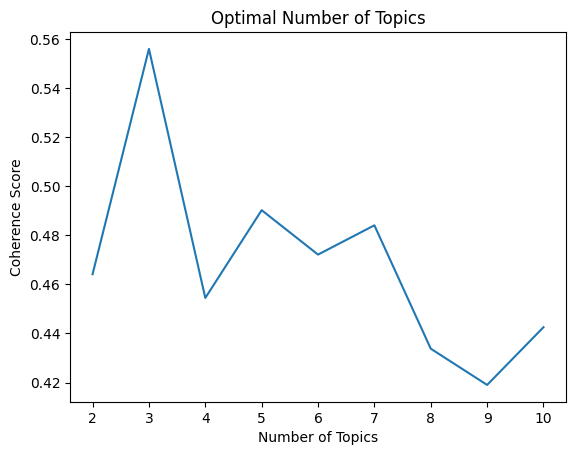

In [ ]:
from gensim.models.coherencemodel import CoherenceModel

coherence_scores = []
for k in range(2, 11):
    lda_model = gensim.models.LdaModel(corpus=corpus,
                                       id2word=dictionary,
                                       num_topics=k,
                                       random_state=123,
                                       update_every=1,
                                       passes=10,
                                       per_word_topics=True)

    coherence_model = CoherenceModel(model=lda_model, texts=df['tokens'], dictionary=dictionary, coherence='c_v')
    coherence = coherence_model.get_coherence()
    coherence_scores.append((k, coherence))

# Plotting coherence scores
x, y = zip(*coherence_scores)
plt.plot(x, y)
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score")
plt.title("Optimal Number of Topics")
plt.show()

Input best k = 3

In [ ]:
best_k = 3
lda_model = gensim.models.LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=best_k,
    random_state=123,
    passes=10,
    per_word_topics=True
)

showing the Top Terms in Each Topic

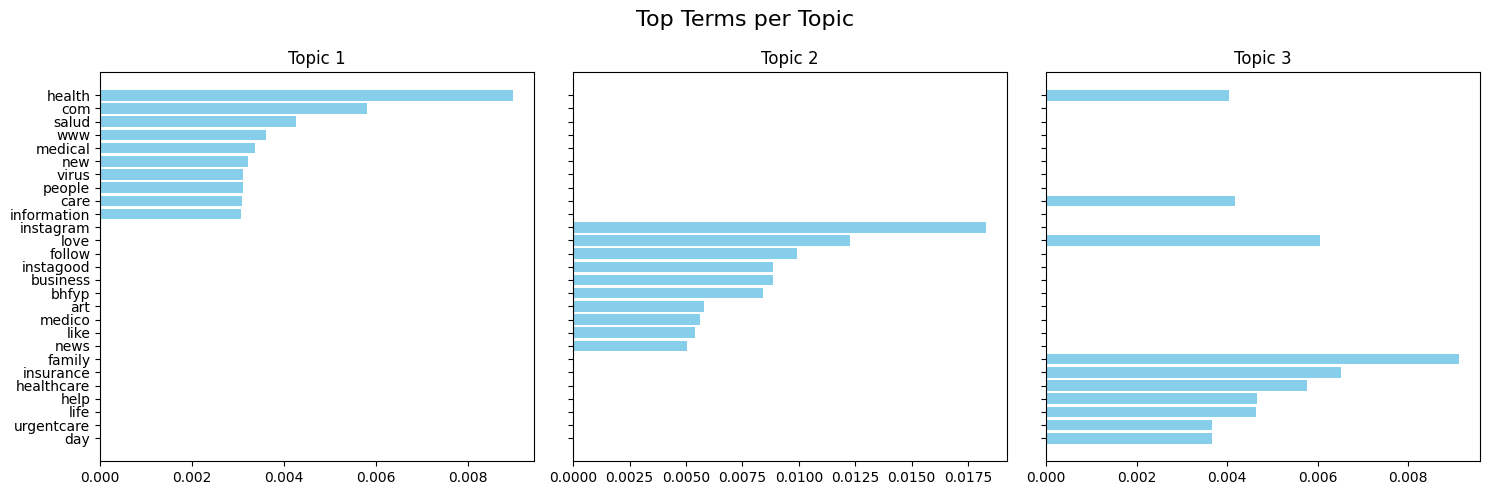

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extracting top words per topic
topics = lda_model.show_topics(formatted=False, num_words=10)

# Creating a DataFrame
topic_terms = []
for topic_num, word_probs in topics:
    for word, prob in word_probs:
        topic_terms.append((topic_num + 1, word, prob))  # topic_num +1 for 1-indexing

df_topics = pd.DataFrame(topic_terms, columns=["Topic", "Word", "Weight"])

# Plot with subplots
fig, axes = plt.subplots(1, len(df_topics["Topic"].unique()), figsize=(15, 5), sharey=True)

for i, topic in enumerate(sorted(df_topics["Topic"].unique())):
    topic_data = df_topics[df_topics["Topic"] == topic]
    axes[i].barh(topic_data["Word"], topic_data["Weight"], color='skyblue')
    axes[i].set_title(f"Topic {topic}")
    axes[i].invert_yaxis()  # most probable words at top

plt.suptitle("Top Terms per Topic", fontsize=16)
plt.tight_layout()
plt.show()

WHAT WERE THE DOMINANT TOPICS OVER TIME

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from gensim import corpora, models

# Set up
stop_words = set(stopwords.words('english') + [
    "covid", "coronavirus", "covidtesting", "covidvaccine", "covid19",
    "link", "https", "bio", "pandemic", "update", "india"
])

# Preprocessing function
def preprocess(text):
    tokens = re.findall(r'\b[a-z]{3,}\b', str(text).lower())
    return [word for word in tokens if word not in stop_words]

# Apply to both languages
df = df.dropna(subset=['post', 'Date', 'Language'])
df['tokens'] = df['post'].apply(preprocess)
df['year'] = pd.to_datetime(df['Date']).dt.year

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Build Dictionary & Corpus (for all posts)

In [ ]:
dictionary = corpora.Dictionary(df['tokens'])
corpus = [dictionary.doc2bow(text) for text in df['tokens']]

Train LDA Model

In [ ]:
lda_model = models.LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=3,
    random_state=123,
    passes=10,
    per_word_topics=True
)

Assign Dominant Topic to Each Document

In [ ]:
def get_dominant_topic(ldamodel, bow):
    topics = ldamodel.get_document_topics(bow)
    return max(topics, key=lambda x: x[1])[0]

df['dominant_topic'] = [get_dominant_topic(lda_model, bow) for bow in corpus]

Topic Labels

In [ ]:
topic_labels = {0: "Public Health and Medical Information", 1: "Social Media Engagement and Online Communication", 2: "Societal Concerns and Emotional Responses"}
df['topic_label'] = df['dominant_topic'].map(topic_labels)

Group by Year and Topic

In [ ]:
yearly_topics = df.groupby(['year', 'topic_label']).size().reset_index(name='count')

# Pivot for stacked area chart
pivot_year = yearly_topics.pivot(index='year', columns='topic_label', values='count').fillna(0)

Plot Topics by Year

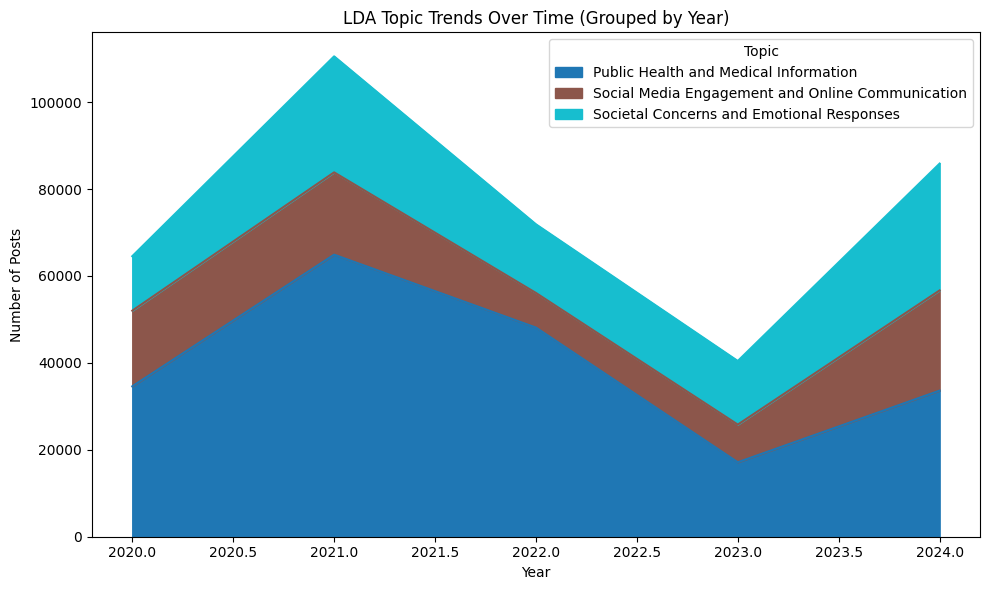

In [ ]:
import matplotlib.pyplot as plt

pivot_year.plot(kind='area', stacked=True, figsize=(10,6), colormap='tab10')
plt.title("LDA Topic Trends Over Time (Grouped by Year)")
plt.xlabel("Year")
plt.ylabel("Number of Posts")
plt.legend(title="Topic")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Group and Plot by Language

In [ ]:
# Group by language + year + topic
lang_topics = df.groupby(['Language', 'year', 'topic_label']).size().reset_index(name='count')

# Pivot for each language
pivot_en = lang_topics[lang_topics['Language'] == 'English'].pivot(index='year', columns='topic_label', values='count').fillna(0)
pivot_es = lang_topics[lang_topics['Language'] == 'Spanish'].pivot(index='year', columns='topic_label', values='count').fillna(0)

Plot English vs Spanish

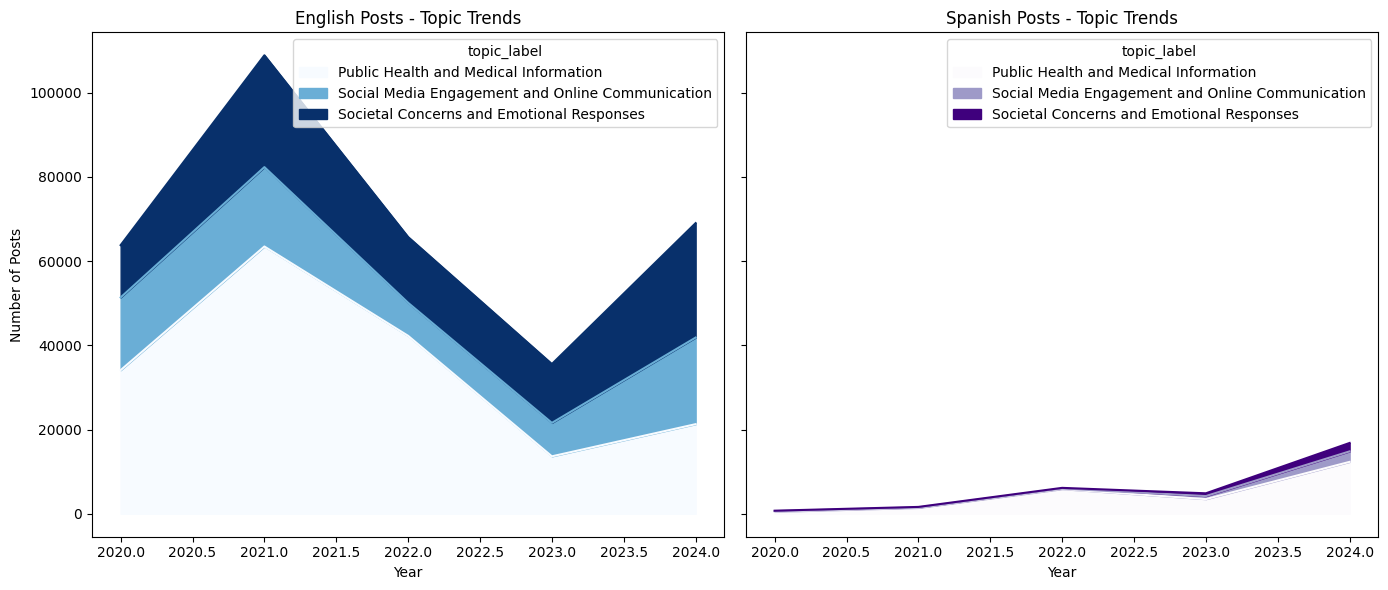

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

pivot_en.plot(kind='area', stacked=True, ax=axes[0], colormap='Blues')
axes[0].set_title("English Posts - Topic Trends")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Posts")

pivot_es.plot(kind='area', stacked=True, ax=axes[1], colormap='Purples')
axes[1].set_title("Spanish Posts - Topic Trends")
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.show()